In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.animation import FuncAnimation, PillowWriter
import os

dataset_path = "spotify_top_1000_tracks.csv"
df = pd.read_csv(dataset_path, encoding="utf-8")

df['duration_min'] = pd.to_numeric(df['duration_min'], errors='coerce')
df['popularity'] = pd.to_numeric(df['popularity'], errors='coerce')

if 'year' not in df.columns:
    df['year'] = pd.to_datetime(
        df['release_date'], errors='coerce'
    ).dt.year

df['year'] = pd.to_numeric(df['year'], errors='coerce')

student_name = "Acapulco Michael"
student_id = "TUPM-26-1875"

color_bar = "darkred"
color_line = "royalblue"
cmap_color = "YlOrRd"

print("Dataset loaded successfully!")
print(df.head())

Dataset loaded successfully!
                 track_name          artist  \
0  All The Stars (with SZA)  Kendrick Lamar   
1                   Starboy      The Weeknd   
2                  Señorita    Shawn Mendes   
3                Heat Waves   Glass Animals   
4           Let Me Love You        DJ Snake   

                                               album release_date  popularity  \
0  Black Panther The Album Music From And Inspire...   2018-02-09          95   
1                                            Starboy   2016-11-25          90   
2                                           Señorita   2019-06-21          80   
3                                          Dreamland   2020-08-07          87   
4                                             Encore   2016-08-05          87   

                                         spotify_url                      id  \
0  https://open.spotify.com/track/3GCdLUSnKSMJhs4...  3GCdLUSnKSMJhs4Tj6CV3s   
1  https://open.spotify.com/track/7MXVkk9

TOP 10 LONGEST TRACKS
                                     track_name                artist  duration_min
                                       Lost Boy                 Jaden      9.497883
                              I'm Getting Ready   Tasha Cobbs Leonard      8.436667
                                        Mirrors     Justin Timberlake      8.069100
What Goes Around.../...Comes Around (Interlude)     Justin Timberlake      7.476217
                             Achilles Come Down        Gang of Youths      7.035767
                           Never Let Go (Of Me)                Baltra      6.909833
          House Of Balloons / Glass Table Girls            The Weeknd      6.753550
                                           Stan                Eminem      6.735100
                                      Galvanize The Chemical Brothers      6.563550
                                    After Hours            The Weeknd      6.017100


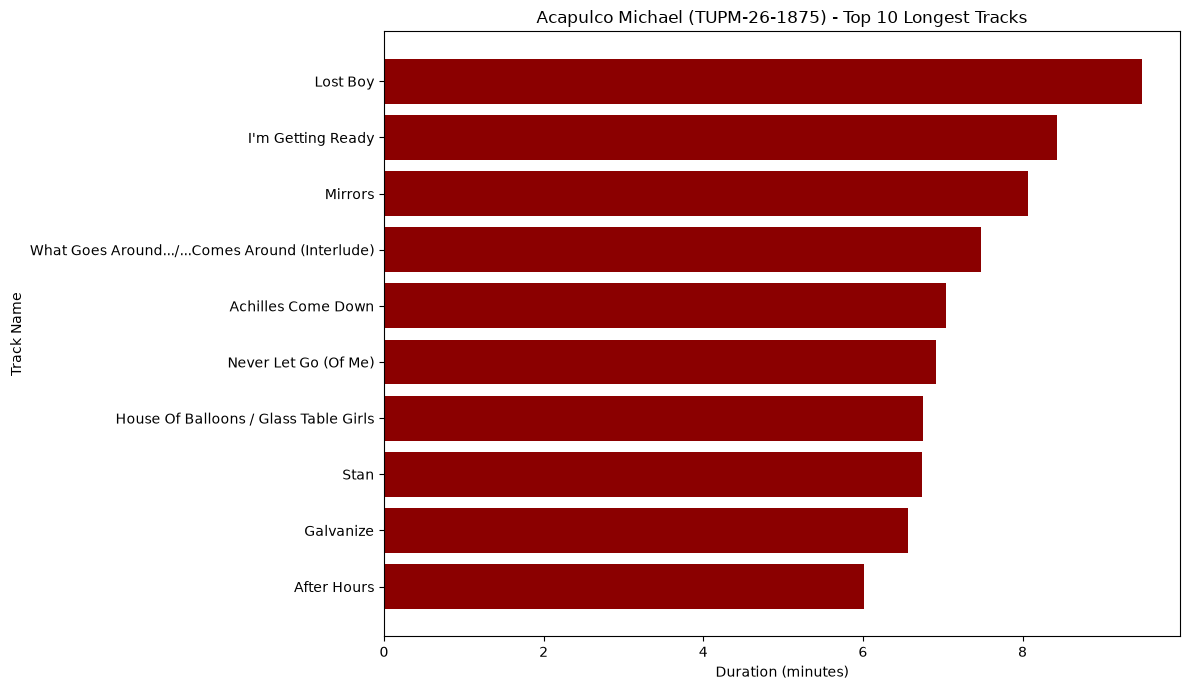

In [5]:
longest_tracks = df.sort_values(
    by='duration_min',
    ascending=False
).head(10)

print("TOP 10 LONGEST TRACKS")
print(longest_tracks[
    ['track_name', 'artist', 'duration_min']
].to_string(index=False))

plt.figure(figsize=(12, 7))

plt.barh(
    longest_tracks['track_name'],
    longest_tracks['duration_min'],
    color=color_bar
)

plt.title(
    f"{student_name} ({student_id}) - Top 10 Longest Tracks"
)
plt.xlabel("Duration (minutes)")
plt.ylabel("Track Name")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

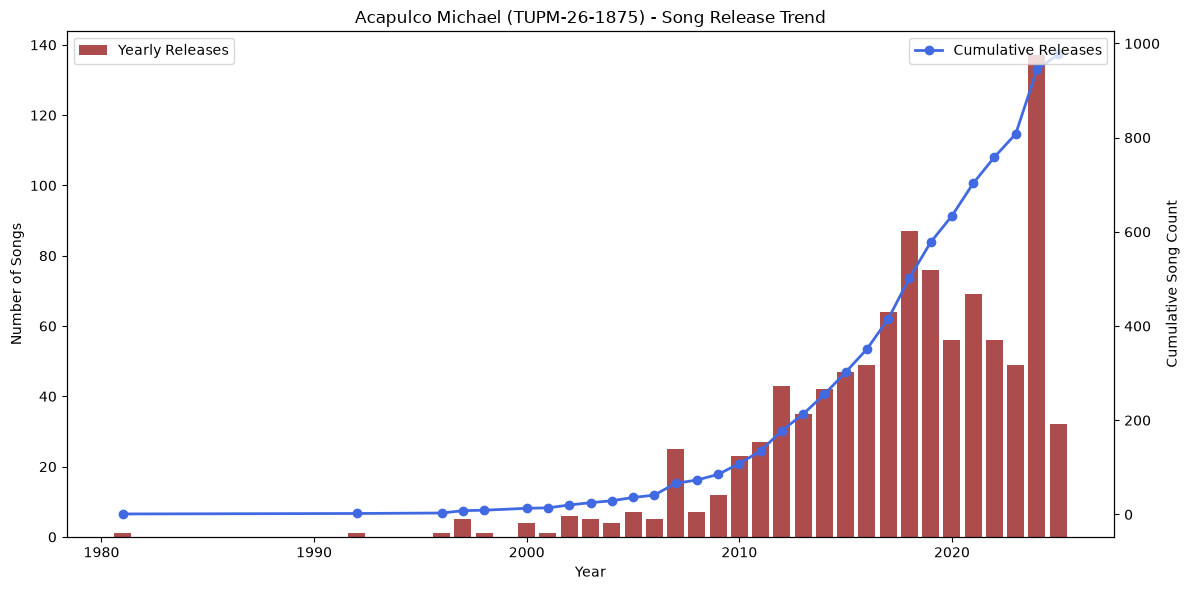

In [6]:
yearly_songs = df.groupby('year').size().reset_index(name='count')

yearly_songs = yearly_songs.dropna(subset=['year'])
yearly_songs = yearly_songs.sort_values('year')

yearly_songs['cumulative'] = yearly_songs['count'].cumsum()

fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.bar(
    yearly_songs['year'],
    yearly_songs['count'],
    color=color_bar,
    alpha=0.7,
    label='Yearly Releases'
)

ax1.set_xlabel("Year")
ax1.set_ylabel("Number of Songs")
ax1.set_title(
    f"{student_name} ({student_id}) - Song Release Trend"
)

ax2 = ax1.twinx()

ax2.plot(
    yearly_songs['year'],
    yearly_songs['cumulative'],
    color=color_line,
    marker='o',
    linewidth=2,
    label='Cumulative Releases'
)

ax2.set_ylabel("Cumulative Song Count")

ax1.legend(loc='upper left')
ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()

In [7]:
animation_data = df[
    ['duration_min', 'popularity', 'year']
].dropna()

years = sorted(animation_data['year'].unique())

fig, ax = plt.subplots(figsize=(10, 6))

x_min = animation_data['duration_min'].min()
x_max = animation_data['duration_min'].max()
y_min = animation_data['popularity'].min()
y_max = animation_data['popularity'].max()

def animate(i):
    ax.clear()

    current_year = years[i]
    yearly_data = animation_data[
        animation_data['year'] == current_year
    ]

    hb = ax.hexbin(
        yearly_data['duration_min'],
        yearly_data['popularity'],
        gridsize=20,
        cmap=cmap_color,
        mincnt=1
    )

    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)

    ax.set_title(
        f"{student_name} ({student_id}) - "
        f"Duration vs Popularity ({int(current_year)})"
    )

    ax.set_xlabel("Duration (minutes)")
    ax.set_ylabel("Popularity")
    ax.grid(alpha=0.2)

    return hb,

ani = FuncAnimation(
    fig,
    animate,
    frames=len(years),
    interval=500,
    repeat=False
)

gif_path = os.path.abspath(
    "animated_duration_popularity.gif"
)

ani.save(
    gif_path,
    writer=PillowWriter(fps=2)
)

print("Animation saved successfully!")
print("GIF Location:", gif_path)

plt.close(fig)

Animation saved successfully!
GIF Location: c:\Users\MICHAEL LAWRENCE\Lab8_Data_Visualization_Acapulco\animated_duration_popularity.gif
